# 01 - Exploratory Data Analysis (EDA)

Analisis eksplorasi awal dataset stunting balita Jeneponto.
Notebook ini **hanya eksplorasi saja** dan tidak melakukan cleaning/perbaikan data apa pun.

Target penelitian: kolom `Height for Age` (Stunted / Not Stunted).
Fitur mentah (variabel independen): `Gender`, `Age (Month)`, `Weight`, `Height`.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5) #buat ngatur ukuran default figure (width, height)
pd.set_option("display.max_columns", None) #tampilkan semua kolom saat print dataframe

In [2]:
DATA_PATH = "../data/raw/Overall Data.xlsx"
df = pd.read_excel(DATA_PATH)
df.shape

(40071, 11)

In [3]:
df.dtypes

No.                    int64
Gender                   str
Age (Month)          float64
Weight                object
Height               float64
Weight for Age           str
Z-Score  W/A          object
Height for Age           str
Z-Score H/A           object
Weight for Height        str
Z-Score W/H           object
dtype: object

In [4]:
df.head()

,No.,Gender,Age (Month),Weight,Height,Weight for Age,Z-Score W/A,Height for Age,Z-Score H/A,Weight for Height,Z-Score W/H
0,1,F,54.0,13.2,97.5,Normal,-1.94,Stunted,-2.11,Normal,-0.95
1,2,M,44.0,12,92.0,Normal,-1.92,Stunted,-2.22,Normal,-0.88
2,3,M,57.0,14,97.0,Normal,-1.9,Stunted,-2.58,Normal,-0.48
3,4,M,26.0,11,79.0,Normal,-1.15,Stunted,-3.11,Normal,0.68
4,5,F,59.0,14.6,98.0,Normal,-1.66,Stunted,-2.49,Normal,-0.18


## Missing Value per Kolom

In [ ]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False) # hilangkan kolom yang tidak memiliki missing value dan mengurutkan dari yang paling banyak
if len(missing) == 0:
    print("Tidak ada missing value di kolom mana pun.")
else:
    print("Kolom dengan missing value:")
    print(missing)

Kolom dengan missing value:
Weight for Height    5
Age (Month)          2
dtype: int64


## Cek Duplikat Baris

In [6]:
n_duplicates = df.duplicated().sum()
print(f"Jumlah baris duplikat: {n_duplicates}")

Jumlah baris duplikat: 0


## Cek Nilai Unik & Konsistensi Kategori

Memeriksa nilai unik pada kolom kategorikal untuk mendeteksi kemungkinan
inkonsistensi label (spasi berlebih, kapitalisasi, atau variasi penulisan)
yang dapat memengaruhi hasil encoding pada tahap preprocessing nanti.


In [7]:
cat_cols = ["Gender", "Height for Age", "Weight for Age", "Weight for Height"]

for col in cat_cols:
    uniq = df[col].dropna().unique()
    print(f"{col} ({len(uniq)} unik): {uniq}\n")


Gender (2 unik): <StringArray>
['F', 'M']
Length: 2, dtype: str

Height for Age (2 unik): <StringArray>
['Stunted', 'Not Stunted']
Length: 2, dtype: str

Weight for Age (4 unik): <StringArray>
['Normal', 'Underfed', 'Malnutrition', 'Overnutrition']
Length: 4, dtype: str

Weight for Height (4 unik): <StringArray>
['Normal', 'Thin', 'Obese', 'Very Thin']
Length: 4, dtype: str



## Distribusi Kelas Target (`Height for Age`)

In [ ]:
target_counts = df["Height for Age"].value_counts(dropna=False)
target_pct = df["Height for Age"].value_counts(dropna=False, normalize=True) * 100

target_dist = pd.DataFrame({"count": target_counts, "percentage": target_pct.round(2)})# 2 angka blkg koma
target_dist

,count,percentage
Height for Age,,
Not Stunted,23867,59.56
Stunted,16204,40.44


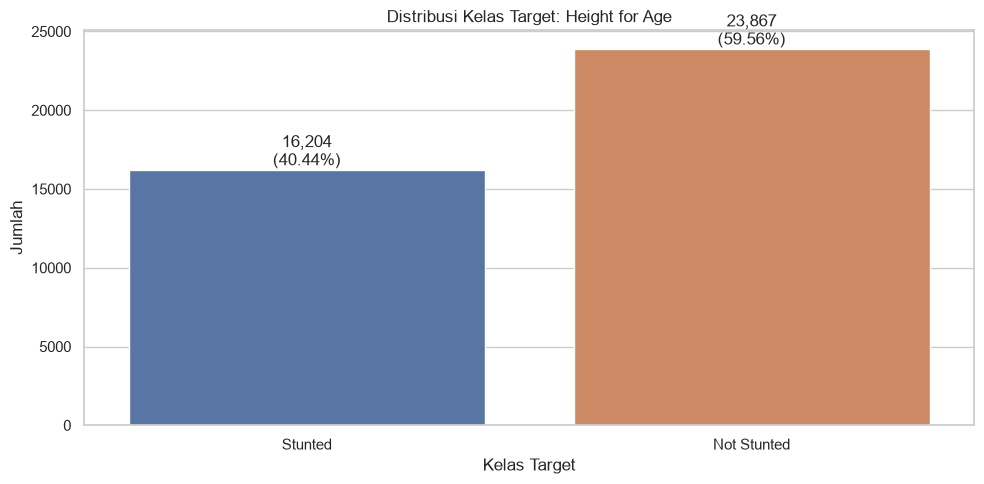

In [9]:
ax = sns.countplot(data=df, x="Height for Age", hue="Height for Age", legend=False)
ax.set_title("Distribusi Kelas Target: Height for Age")
ax.set_xlabel("Kelas Target")
ax.set_ylabel("Jumlah")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}\n({p.get_height()/len(df)*100:.2f}%)",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.show()

### Catatan: Keseimbangan Kelas

Distribusi target relatif **seimbang** (Not Stunted ≈ 60% vs Stunted ≈ 40%),
bukan imbalance ekstrem (rasio ≈ 1.47 : 1). Karena kelas tidak terlalu timpang,
manfaat SMOTE-ENN perlu dievaluasi dengan membandingkan metrik **sebelum vs sesudah**
resampling.


## Visualisasi Distribusi Fitur Mentah

Fitur: `Gender` (kategorikal), `Age (Month)` (numerik), `Height` (numerik).

`Weight` tidak divisualisasikan di sini karena masih korup (campuran tipe data),
dan dibahas tersendiri pada bagian inspeksi data-quality di bawah.


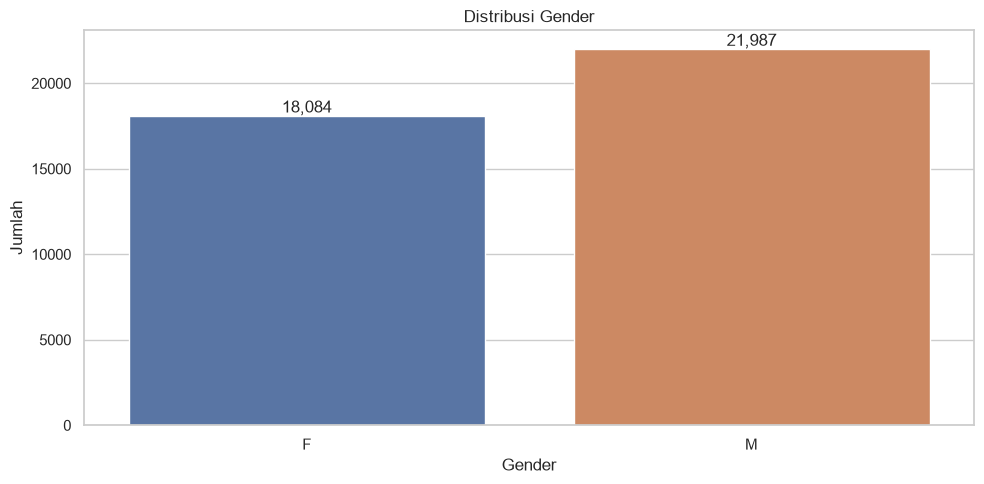

In [10]:
ax = sns.countplot(data=df, x="Gender", hue="Gender", legend=False)
ax.set_title("Distribusi Gender")
ax.set_xlabel("Gender")
ax.set_ylabel("Jumlah")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.show()

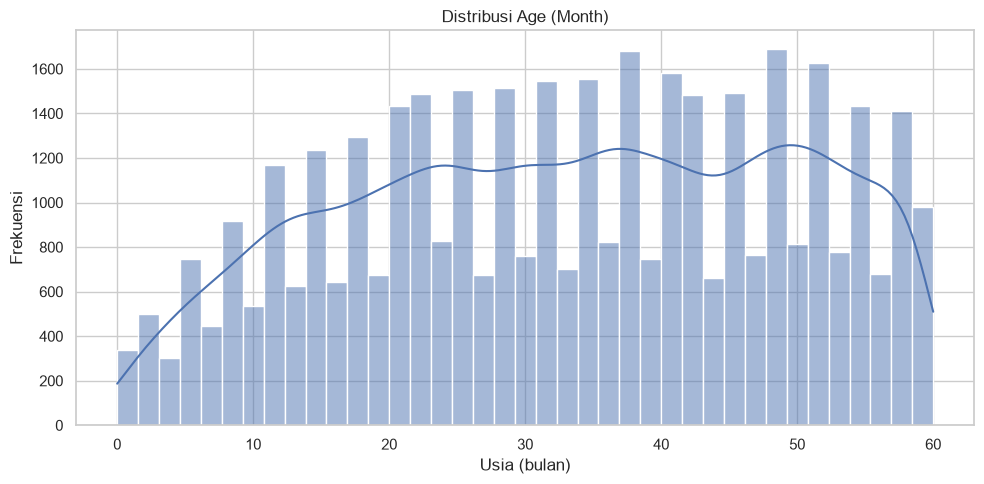

In [11]:
ax = sns.histplot(df["Age (Month)"].dropna(), kde=True)
ax.set_title("Distribusi Age (Month)")
ax.set_xlabel("Usia (bulan)")
ax.set_ylabel("Frekuensi")
plt.tight_layout()
plt.show()

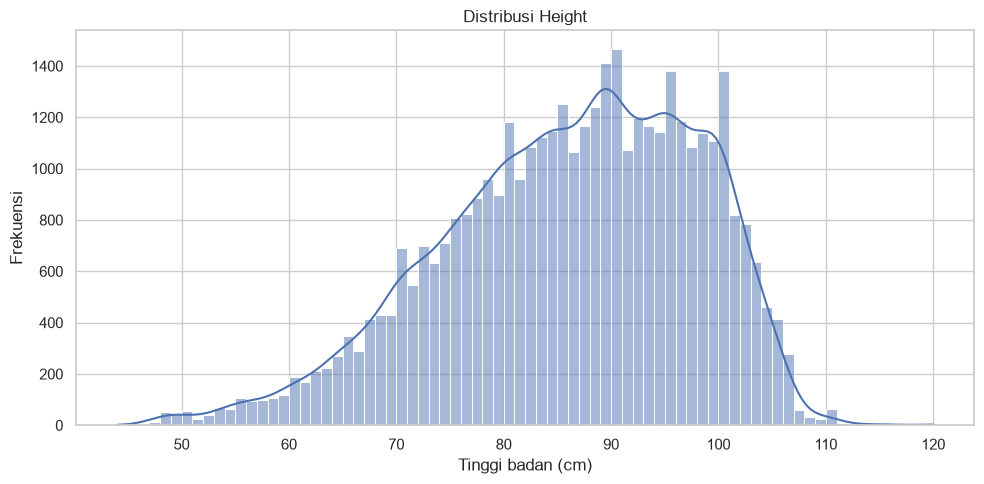

In [12]:
ax = sns.histplot(df["Height"].dropna(), kde=True)
ax.set_title("Distribusi Height")
ax.set_xlabel("Tinggi badan (cm)")
ax.set_ylabel("Frekuensi")
plt.tight_layout()
plt.show()

## Statistik Deskriptif Fitur Numerik

Ringkasan statistik untuk fitur numerik `Age (Month)` dan `Height`.
Kolom `Weight` **sengaja dikecualikan** karena masih korup (campuran
datetime/int/str) pada data mentah; statistiknya baru sahih setelah
perbaikan di notebook `02_cleaning.ipynb`.


In [13]:
df[["Age (Month)", "Height"]].describe().T


,count,mean,std,min,25%,50%,75%,max
Age (Month),40069.0,33.020664,15.823079,0.0,20.0,34.0,47.0,60.0
Height,40071.0,86.051172,11.816466,44.0,78.0,87.3,95.2,120.0


## Eksplorasi Outlier (Age & Height)

Boxplot untuk melihat keberadaan nilai ekstrem pada `Age (Month)` dan
`Height`. EDA di sini **hanya mendeteksi**, bukan menghapus; keputusan
penanganan outlier ditunda ke tahap preprocessing. `Weight` dikecualikan
karena masih korup pada data mentah.


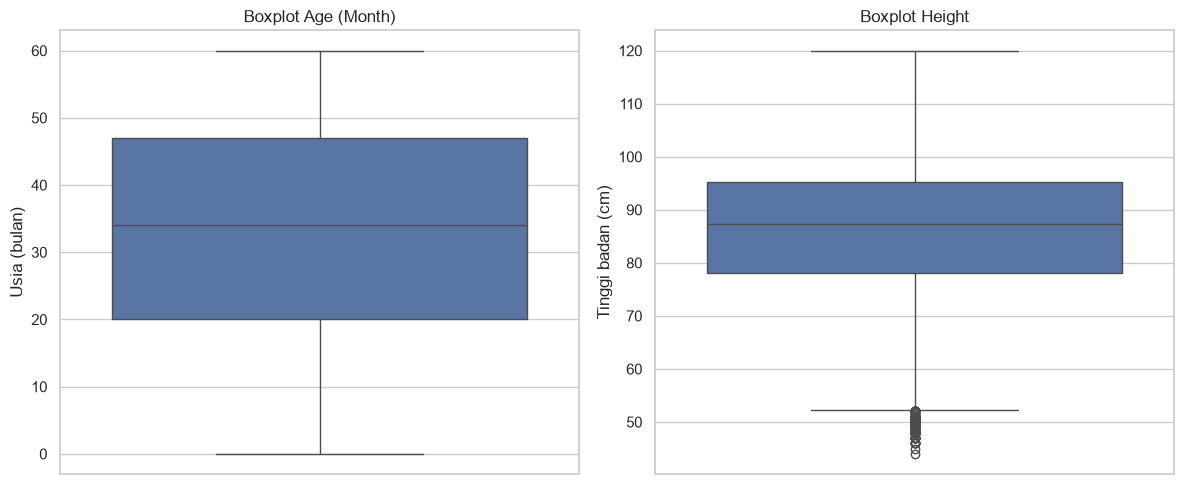

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, y="Age (Month)", ax=axes[0])
axes[0].set_title("Boxplot Age (Month)")
axes[0].set_ylabel("Usia (bulan)")

sns.boxplot(data=df, y="Height", ax=axes[1])
axes[1].set_title("Boxplot Height")
axes[1].set_ylabel("Tinggi badan (cm)")

plt.tight_layout()
plt.show()


## Hubungan Fitur dengan Target (`Height for Age`)

Melihat apakah fitur mentah mampu membedakan kelas `Stunted` vs
`Not Stunted`. `Weight` dikecualikan di sini (masih korup), analisisnya
menyusul setelah cleaning. Fokus: `Age (Month)`, `Height`, dan `Gender`.


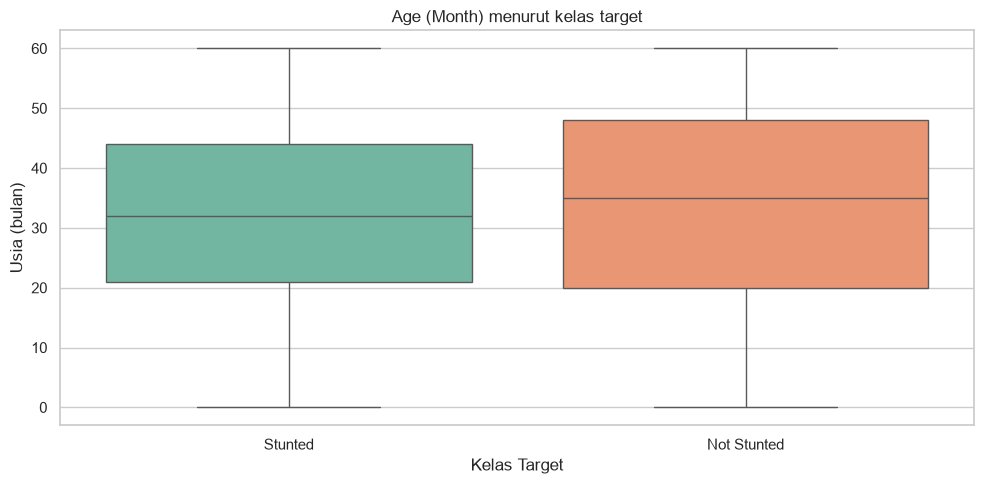

In [15]:
ax = sns.boxplot(data=df, x="Height for Age", y="Age (Month)", hue="Height for Age", legend=False, palette="Set2")
ax.set_title("Age (Month) menurut kelas target")
ax.set_xlabel("Kelas Target")
ax.set_ylabel("Usia (bulan)")
plt.tight_layout()
plt.show()


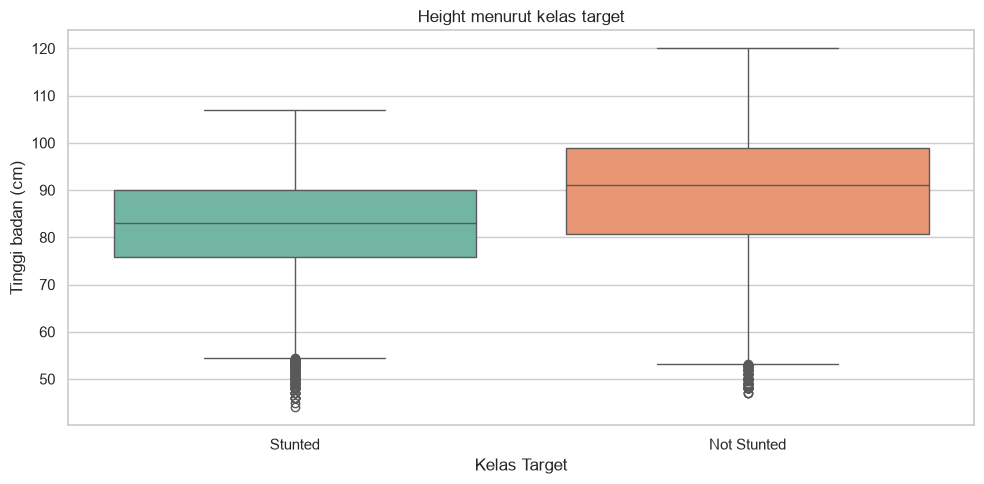

In [16]:
ax = sns.boxplot(data=df, x="Height for Age", y="Height", hue="Height for Age", legend=False, palette="Set2")
ax.set_title("Height menurut kelas target")
ax.set_xlabel("Kelas Target")
ax.set_ylabel("Tinggi badan (cm)")
plt.tight_layout()
plt.show()


In [17]:
df.groupby("Height for Age")[["Age (Month)", "Height"]].agg(["count", "mean", "median", "std"])


Age (Month)                              Height             \
                     count       mean median        std  count       mean   
Height for Age                                                              
Not Stunted          23865  33.651372   35.0  16.501899  23867  88.720644   
Stunted              16204  32.091767   32.0  14.717976  16204  82.119285   

                                  
               median        std  
Height for Age                    
Not Stunted      91.0  12.135873  
Stunted          83.0  10.119848

### Gender × Target

Crosstab jumlah dan persentase (row-normalized) untuk melihat apakah
proporsi stunting berbeda menurut gender.


In [18]:
pd.crosstab(df["Gender"], df["Height for Age"], margins=True)


Height for Age,Not Stunted,Stunted,All
Gender,,,
F,11207,6877,18084
M,12660,9327,21987
All,23867,16204,40071


In [19]:
pd.crosstab(df["Gender"], df["Height for Age"], normalize="index").mul(100).round(2)


Height for Age,Not Stunted,Stunted
Gender,,
F,61.97,38.03
M,57.58,42.42


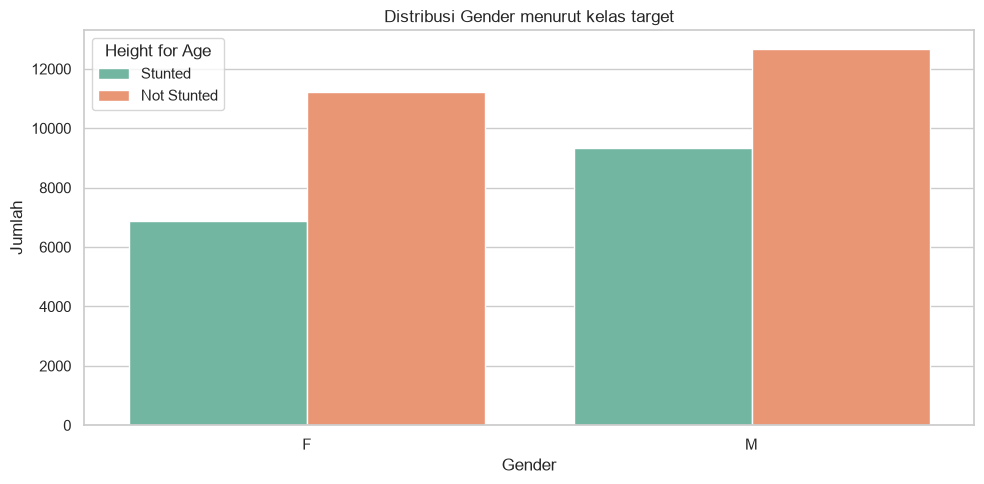

In [20]:
ax = sns.countplot(data=df, x="Gender", hue="Height for Age", palette="Set2")
ax.set_title("Distribusi Gender menurut kelas target")
ax.set_xlabel("Gender")
ax.set_ylabel("Jumlah")
plt.tight_layout()
plt.show()


## Inspeksi Kolom `Weight`

Kolom `Weight` dicurigai rusak akibat auto-konversi Excel: sebagian nilai numerik
(misalnya `2.8`) terbaca sebagai tanggal `datetime`. Berikut kita periksa **tipe data
tiap nilai** di kolom ini (int / str / datetime) tanpa melakukan perbaikan.

In [21]:
weight_dtype_counts = df["Weight"].map(type).value_counts()
print("Distribusi tipe data per nilai pada kolom Weight:")
print(weight_dtype_counts)

Distribusi tipe data per nilai pada kolom Weight:
Weight
<class 'datetime.datetime'>    20158
<class 'int'>                  10780
<class 'str'>                   9133
Name: count, dtype: int64


In [22]:
is_datetime = df["Weight"].map(lambda x: isinstance(x, datetime))
is_int = df["Weight"].map(lambda x: isinstance(x, int))
is_str = df["Weight"].map(lambda x: isinstance(x, str))

n_datetime = is_datetime.sum()
n_int = is_int.sum()
n_str = is_str.sum()

print(f"Total nilai Weight: {len(df)}")
print(f"  - datetime : {n_datetime} ({n_datetime/len(df)*100:.2f}%)")
print(f"  - int      : {n_int} ({n_int/len(df)*100:.2f}%)")
print(f"  - str      : {n_str} ({n_str/len(df)*100:.2f}%)")

Total nilai Weight: 40071
  - datetime : 20158 (50.31%)
  - int      : 10780 (26.90%)
  - str      : 9133 (22.79%)


In [23]:
print("Contoh nilai Weight yang terbaca sebagai datetime:")
datetime_examples = df.loc[is_datetime, "Weight"].head(20)
datetime_examples

Contoh nilai Weight yang terbaca sebagai datetime:


12300    2025-02-08 00:00:00
12301    2025-07-14 00:00:00
12303    2025-05-12 00:00:00
12304    2025-04-10 00:00:00
12306    2025-06-16 00:00:00
12310    2025-02-13 00:00:00
12312    2025-04-15 00:00:00
12313    2025-09-13 00:00:00
12314    2025-05-15 00:00:00
12315    2025-08-14 00:00:00
12318    2025-03-15 00:00:00
12320    2025-08-15 00:00:00
12323    2025-02-15 00:00:00
12325    2025-08-15 00:00:00
12326    2025-03-25 00:00:00
12328    2025-06-14 00:00:00
12329    2025-08-14 00:00:00
12330    2025-01-13 00:00:00
12331    2025-04-13 00:00:00
12332    2025-01-16 00:00:00
Name: Weight, dtype: object

In [24]:
print("Contoh nilai Weight yang terbaca sebagai string:")
df.loc[is_str, "Weight"].head(20)

Contoh nilai Weight yang terbaca sebagai string:


0     13.2
4     14.6
8     14.2
10    11.5
11    13.1
13    11.1
14    11.1
16     9.5
17    14.7
18    11.2
21    12.3
22    14.3
23    14.4
24    14.4
25    13.2
26    10.3
27    12.5
28    11.7
29    14.2
30    14.7
Name: Weight, dtype: object

## Ringkasan Temuan EDA

1. Dataset 40.071 baris × 11 kolom, tanpa duplikat.
2. Missing value minor: `Age (Month)` (2) dan `Weight for Height` (5).
3. Target `Height for Age` relatif seimbang: Not Stunted 59.56% vs Stunted 40.44%.
4. Kolom `Weight` korup (≈ 50% terbaca datetime akibat auto-konversi Excel).
5. Dari boxplot, `Height` dan `Age` tampak berbeda antara Stunted/Not Stunted,
   indikasi awal kedua fitur tersebut informatif.
6. Kolom turunan (`Weight for Age`, `Z-Score`, dll.) berpotensi data-leakage
   dan akan dibuang di preprocessing.
